In [ ]:
# Thiết lập môi trường làm việc (tự động phát hiện Google Colab hoặc Local)
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    colab_dir = "/content/drive/MyDrive/ColabNotebooks/Noron&DeepLearning/techtrail-ai-engine-v1"
    if os.path.exists(colab_dir):
        %cd {colab_dir}
except Exception:
    pass

print("Đường dẫn làm việc hiện tại:", os.getcwd())
print("Danh sách file trong data/:", os.listdir('data') if os.path.exists('data') else "Chưa có thư mục data")


Đường dẫn làm việc hiện tại: D:\coding\My AI project\techtrail-ai-engine-v1
Danh sách file trong data/: ['resume-dataset.csv', 'test.csv', 'train.csv', 'val.csv']


## Chia data thành 70-15-15: train-test-validation


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

os.makedirs("data", exist_ok=True)

train_path = "data/train.csv"
val_path = "data/val.csv"
test_path = "data/test.csv"

# Cờ FORCE_RE_SPLIT: Đặt True để ép buộc chia lại từ dataset gốc mới nhất; False: ưu tiên đọc file đã chia sẵn
FORCE_RE_SPLIT = True

splits_exist = (
    os.path.exists(train_path) and os.path.getsize(train_path) > 0 and
    os.path.exists(val_path) and os.path.getsize(val_path) > 0 and
    os.path.exists(test_path) and os.path.getsize(test_path) > 0
)

if splits_exist and not FORCE_RE_SPLIT:
    print("Phát hiện các file train.csv, val.csv, test.csv đã có sẵn trong data/. Đang tải...")
    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)
    
    # Chuẩn hóa bảng ánh xạ Category <-> Label ID từ dữ liệu có sẵn
    if 'category' in train_df.columns and 'label' in train_df.columns:
        cat_label_df = train_df[['category', 'label']].drop_duplicates().sort_values('label')
        category_to_id = dict(zip(cat_label_df['category'], cat_label_df['label']))
        id_to_category = dict(zip(cat_label_df['label'], cat_label_df['category']))
    else:
        unique_categories = sorted(train_df['category'].unique())
        category_to_id = {cat: idx for idx, cat in enumerate(unique_categories)}
        id_to_category = {idx: cat for cat, idx in category_to_id.items()}
        train_df['label'] = train_df['category'].map(category_to_id)
        val_df['label'] = val_df['category'].map(category_to_id)
        test_df['label'] = test_df['category'].map(category_to_id)
    
    print("Đã tải thành công dữ liệu từ các file có sẵn!")

else:
    print("Tiến hành nạp và phân chia lại từ dataset gốc mới nhất (FORCE_RE_SPLIT=True)...\n")
    
    # 1. Nạp file dataset gốc từ thư mục data/
    data_file = 'data/resume-dataset.csv'
    if not (os.path.exists(data_file) and os.path.getsize(data_file) > 0):
        other_csvs = [
            os.path.join('data', f) for f in os.listdir('data')
            if f.endswith('.csv') and not f.startswith(('train', 'val', 'test'))
        ]
        if other_csvs:
            data_file = other_csvs[0]
        else:
            raise FileNotFoundError("Không tìm thấy file dataset gốc nào trong thư mục data/!")

    print(f"Đang đọc dữ liệu từ: {data_file}")
    df = pd.read_csv(data_file)
    print(f"Đã tải {len(df)} dòng dữ liệu từ {data_file}")

    # 2. Chuẩn hóa tên cột
    text_col = None
    for col in ['Resume', 'text_sequence', 'clean_text', 'text', 'resume']:
        if col in df.columns:
            text_col = col
            break
    if text_col is None:
        raise KeyError(f"Không tìm thấy cột văn bản trong các cột: {df.columns.tolist()}")

    cat_col = None
    for col in ['Category', 'category', 'label']:
        if col in df.columns:
            cat_col = col
            break
    if cat_col is None:
        raise KeyError(f"Không tìm thấy cột ngành nghề trong các cột: {df.columns.tolist()}")

    # Ánh xạ nhãn Category thành số nguyên (0..N-1)
    unique_categories = sorted(df[cat_col].unique())
    category_to_id = {cat: idx for idx, cat in enumerate(unique_categories)}
    id_to_category = {idx: cat for cat, idx in category_to_id.items()}

    df['text_sequence'] = df[text_col].astype(str)
    df['category'] = df[cat_col]
    df['label'] = df['category'].map(category_to_id)
    if 'id' not in df.columns:
        df['id'] = df.index
    df = df[['id', 'text_sequence', 'category', 'label']]

    # 3. Chia 70-15-15: train-val-test phân tầng theo nhãn
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Lưu ra file CSV
    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    test_df.to_csv(test_path, index=False)
    print("Đã lưu các file train.csv, val.csv, test.csv vào thư mục data/.")

# 4. In thông tin tổng kết
total_len = len(train_df) + len(val_df) + len(test_df)
print(f"\nKích thước các tập dữ liệu:")
print(f"  Train: {len(train_df)} dòng ({len(train_df)/total_len*100:.1f}%)")
print(f"  Val:   {len(val_df)} dòng ({len(val_df)/total_len*100:.1f}%)")
print(f"  Test:  {len(test_df)} dòng ({len(test_df)/total_len*100:.1f}%)")

print("\nBảng ánh xạ nhãn (Category -> Label ID):")
for cat, idx in sorted(category_to_id.items(), key=lambda x: x[1]):
    print(f"  {idx}: {cat}")


Tiến hành nạp và phân chia lại từ dataset gốc mới nhất (FORCE_RE_SPLIT=True)...

Đang đọc dữ liệu từ: data/resume-dataset.csv
Đã tải 2000 dòng dữ liệu từ data/resume-dataset.csv
Đã lưu các file train.csv, val.csv, test.csv vào thư mục data/.

Kích thước các tập dữ liệu:
  Train: 1400 dòng (70.0%)
  Val:   300 dòng (15.0%)
  Test:  300 dòng (15.0%)

Bảng ánh xạ nhãn (Category -> Label ID):
  0: Backend Developer
  1: Cloud Enginee
  2: Data Scientist
  3: Frontend Developer
  4: Full Stack Developer
  5: Machine Learning Engineer
  6: Mobile App Developer (iOS/Android)
  7: Python Developer


## Hàm cắt văn bản thành chuỗi thời gian

In [ ]:
def split_into_time_steps(text, num_steps=3):
    words = str(text).split()
    if len(words) == 0:
        return [""] * num_steps

    chunk_size = max(1, len(words) // num_steps)
    chunks = []

    for i in range(num_steps):
        if i == num_steps - 1:
            chunk = words[i * chunk_size:]
        else:
            chunk = words[i * chunk_size : (i + 1) * chunk_size]
        chunks.append(" ".join(chunk))

    return chunks

## DataLoader biến chữ thành mảng số

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class TechTrailDataset(Dataset):
    def __init__(self, dataframe, vocab, max_seq_length, num_steps=3):
        self.data = dataframe.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_seq_length
        self.num_steps = num_steps

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = str(row['text_sequence'])
        label = int(row['label'])

        time_steps = split_into_time_steps(text, self.num_steps)

        sequence_tensor = torch.zeros((self.num_steps, self.max_len), dtype=torch.long)

        for step_idx, step_text in enumerate(time_steps):
            tokens = step_text.split()
            token_ids = [self.vocab.get(word, self.vocab.get('<UNK>', 1)) for word in tokens]

            if len(token_ids) > self.max_len:
                token_ids = token_ids[:self.max_len]
            else:
                token_ids = token_ids + [self.vocab.get('<PAD>', 0)] * (self.max_len - len(token_ids))

            sequence_tensor[step_idx] = torch.tensor(token_ids, dtype=torch.long)

        return sequence_tensor, torch.tensor(label, dtype=torch.long)

In [ ]:
from collections import Counter

# 1. Xây dựng từ điển vocab từ tập train
def build_vocab(texts, min_freq=1):
    word_counts = Counter()
    for text in texts:
        word_counts.update(str(text).split())
    vocab = {'<PAD>': 0, '<UNK>': 1}
    for word, count in word_counts.items():
        if count >= min_freq and word not in vocab:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(train_df['text_sequence'])
print(f"Kích thước từ điển (Vocab size): {len(vocab)} từ")

# 2. Khởi tạo Dataset và DataLoader cho cả 3 tập train, val, test
max_seq_length = 50
batch_size = 32

train_dataset = TechTrailDataset(train_df, vocab, max_seq_length=max_seq_length, num_steps=3)
val_dataset = TechTrailDataset(val_df, vocab, max_seq_length=max_seq_length, num_steps=3)
test_dataset = TechTrailDataset(test_df, vocab, max_seq_length=max_seq_length, num_steps=3)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3. Kiểm tra thử 1 batch từ train_loader
for batch_x, batch_y in train_loader:
    print("\nKiểm tra 1 batch từ DataLoader thành công:")
    print("  Batch X shape (batch_size, num_steps, max_seq_length):", batch_x.shape)
    print("  Batch Y shape (batch_size):", batch_y.shape)
    print("  Nhãn số trong batch:", batch_y[:8].tolist())
    print("  Tên ngành nghề tương ứng:", [id_to_category[y.item()] for y in batch_y[:8]])
    break

Kích thước từ điển (Vocab size): 1649 từ

Kiểm tra 1 batch từ DataLoader thành công:
  Batch X shape (batch_size, num_steps, max_seq_length): torch.Size([32, 3, 50])
  Batch Y shape (batch_size): torch.Size([32])
  Nhãn số trong batch: [2, 7, 7, 1, 0, 7, 1, 1]
  Tên ngành nghề tương ứng: ['Data Scientist', 'Python Developer', 'Python Developer', 'Cloud Enginee', 'Backend Developer', 'Python Developer', 'Cloud Enginee', 'Cloud Enginee']


## 1. Cài đặt Kiến trúc Mô hình RNN và LSTM

Mỗi phản hồi/hồ sơ của ứng viên được chia thành $T=3$ bước thời gian, mỗi bước chứa chuỗi từ (tối đa $L=50$ tokens).
- **Embedding Layer**: Mã hóa các token ID thành vector embedding (`embed_dim = 128`).
- **Masked Mean Pooling**: Tính vector đại diện từng bước phản hồi, bỏ qua token đệm `<PAD>`.
- **RNN / LSTM Layer**: Mô hình hóa sự phụ thuộc theo chuỗi thời gian qua các bước phản hồi.
- **Linear Classifier**: Phân loại ra 8 nhóm ngành nghề CNTT.

In [ ]:
import torch
import torch.nn as nn

class TechTrailRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_classes=len(category_to_id), num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            nonlinearity='tanh',
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x: (batch_size, num_steps, max_len)
        embeds = self.embedding(x)  # (B, S, L, D)
        mask = (x != 0).unsqueeze(-1).float()  # (B, S, L, 1)
        sum_embeds = (embeds * mask).sum(dim=2)  # (B, S, D)
        lengths = mask.sum(dim=2).clamp(min=1e-9)
        step_features = self.dropout(sum_embeds / lengths)

        out, hn = self.rnn(step_features)
        last_hidden = hn[-1]  # (B, hidden_dim)
        logits = self.fc(last_hidden)
        return logits

class TechTrailLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_classes=len(category_to_id), num_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        # x: (batch_size, num_steps, max_len)
        embeds = self.embedding(x)
        mask = (x != 0).unsqueeze(-1).float()
        sum_embeds = (embeds * mask).sum(dim=2)
        lengths = mask.sum(dim=2).clamp(min=1e-9)
        step_features = self.dropout(sum_embeds / lengths)

        out, (hn, cn) = self.lstm(step_features)
        last_hidden = hn[-1]
        logits = self.fc(last_hidden)
        return logits

# Khởi tạo thử mô hình LSTM
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sample_model = TechTrailLSTM(vocab_size=len(vocab), embed_dim=128, hidden_dim=128, num_classes=len(category_to_id)).to(device)
print(f"Khởi tạo thành công mô hình TechTrailLSTM trên thiết bị: {device}")
total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)


Khởi tạo thành công mô hình TechTrailLSTM trên thiết bị: cuda
Tổng số tham số có thể huấn luyện: 344,200


## 2. Thiết lập Loss Function, Optimizer & Vòng lặp Huấn luyện (Training Loop)

- **Loss Function**: `nn.CrossEntropyLoss()` (chuẩn hóa Softmax và tính Negative Log Likelihood Loss).
- **Optimizer**: `Adam(lr=0.002, weight_decay=1e-4)`.
- **Learning Rate Scheduler**: `ReduceLROnPlateau` tự động giảm tốc độ học khi hàm mất mát chững lại.
- **Early Stopping**: Tự động dừng huấn luyện khi Loss trên tập validation không cải thiện sau $N$ epochs, đồng thời lưu trọng số tốt nhất.

In [ ]:
import os
import time
import numpy as np
import torch.optim as optim

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for batch_x, batch_y in dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)
        preds = logits.argmax(dim=1)
        total_correct += (preds == batch_y).sum().item()
        total_samples += batch_x.size(0)

    return total_loss / total_samples, total_correct / total_samples

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            total_loss += loss.item() * batch_x.size(0)
            preds = logits.argmax(dim=1)
            total_correct += (preds == batch_y).sum().item()
            total_samples += batch_x.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())

    return total_loss / total_samples, total_correct / total_samples, np.array(all_preds), np.array(all_labels)

def train_model(model, train_loader, val_loader, epochs=15, lr=2e-3, patience=5, save_name='best_model.pt'):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    os.makedirs('checkpoints', exist_ok=True)
    save_path = os.path.join('checkpoints', save_name)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')
    patience_counter = 0

    print(f"Bắt đầu huấn luyện mô hình ({epochs} epochs tối đa)...")
    print("=" * 75)
    print(f"{'Epoch':<8} | {'Train Loss':<12} | {'Train Acc':<11} | {'Val Loss':<11} | {'Val Acc':<10} | {'Trạng thái'}")
    print("=" * 75)

    start_time = time.time()
    for epoch in range(1, epochs + 1):
        t_loss, t_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        v_loss, v_acc, _, _ = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(t_loss)
        history['train_acc'].append(t_acc)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)

        scheduler.step(v_loss)
        status = ""
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save(model.state_dict(), save_path)
            status = "(*) Lưu model tốt nhất"
            patience_counter = 0
        else:
            patience_counter += 1

        print(f"{epoch:02d}/{epochs:02d}    | {t_loss:<12.4f} | {t_acc*100:<10.2f}% | {v_loss:<11.4f} | {v_acc*100:<9.2f}% | {status}")
        if patience_counter >= patience:
            print(f"\n[HỘI TỤ] Hàm mất mát không giảm thêm sau {patience} epochs liên tiếp. Dừng sớm tại Epoch {epoch}.")
            break

    elapsed = time.time() - start_time
    print("=" * 75)
    print(f"Hoàn thành huấn luyện trong: {elapsed:.2f} giây! Checkpoint đã lưu tại '{save_path}'")
    return history, save_path

## 3. Huấn luyện Mô hình LSTM cho đến khi Loss hội tụ

In [ ]:
# Khởi tạo mô hình TechTrailLSTM
lstm_model = TechTrailLSTM(
    vocab_size=len(vocab),
    embed_dim=128,
    hidden_dim=128,
    num_classes=len(category_to_id),
    dropout=0.3
).to(device)

# Chạy huấn luyện đến khi hội tụ
lstm_history, best_lstm_ckpt = train_model(
    lstm_model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.002,
    patience=5,
    save_name='best_lstm_model.pt'
)

Bắt đầu huấn luyện mô hình (15 epochs tối đa)...
Epoch    | Train Loss   | Train Acc   | Val Loss    | Val Acc    | Trạng thái
01/15    | 2.0161       | 27.71     % | 1.7626      | 49.33    % | (*) Lưu model tốt nhất
02/15    | 1.0394       | 62.64     % | 0.5767      | 79.33    % | (*) Lưu model tốt nhất
03/15    | 0.4525       | 83.93     % | 0.2998      | 89.67    % | (*) Lưu model tốt nhất
04/15    | 0.2888       | 89.57     % | 0.2237      | 92.33    % | (*) Lưu model tốt nhất
05/15    | 0.1948       | 93.64     % | 0.1679      | 94.00    % | (*) Lưu model tốt nhất
06/15    | 0.1589       | 94.64     % | 0.1157      | 95.67    % | (*) Lưu model tốt nhất
07/15    | 0.1085       | 96.29     % | 0.0934      | 97.00    % | (*) Lưu model tốt nhất
08/15    | 0.0697       | 97.50     % | 0.0691      | 97.67    % | (*) Lưu model tốt nhất
09/15    | 0.0561       | 98.07     % | 0.0824      | 97.67    % | 
10/15    | 0.0459       | 98.36     % | 0.0671      | 97.67    % | (*) Lưu model tốt 

## 4. Trực quan hóa Quá trình Hội tụ của Loss và Accuracy

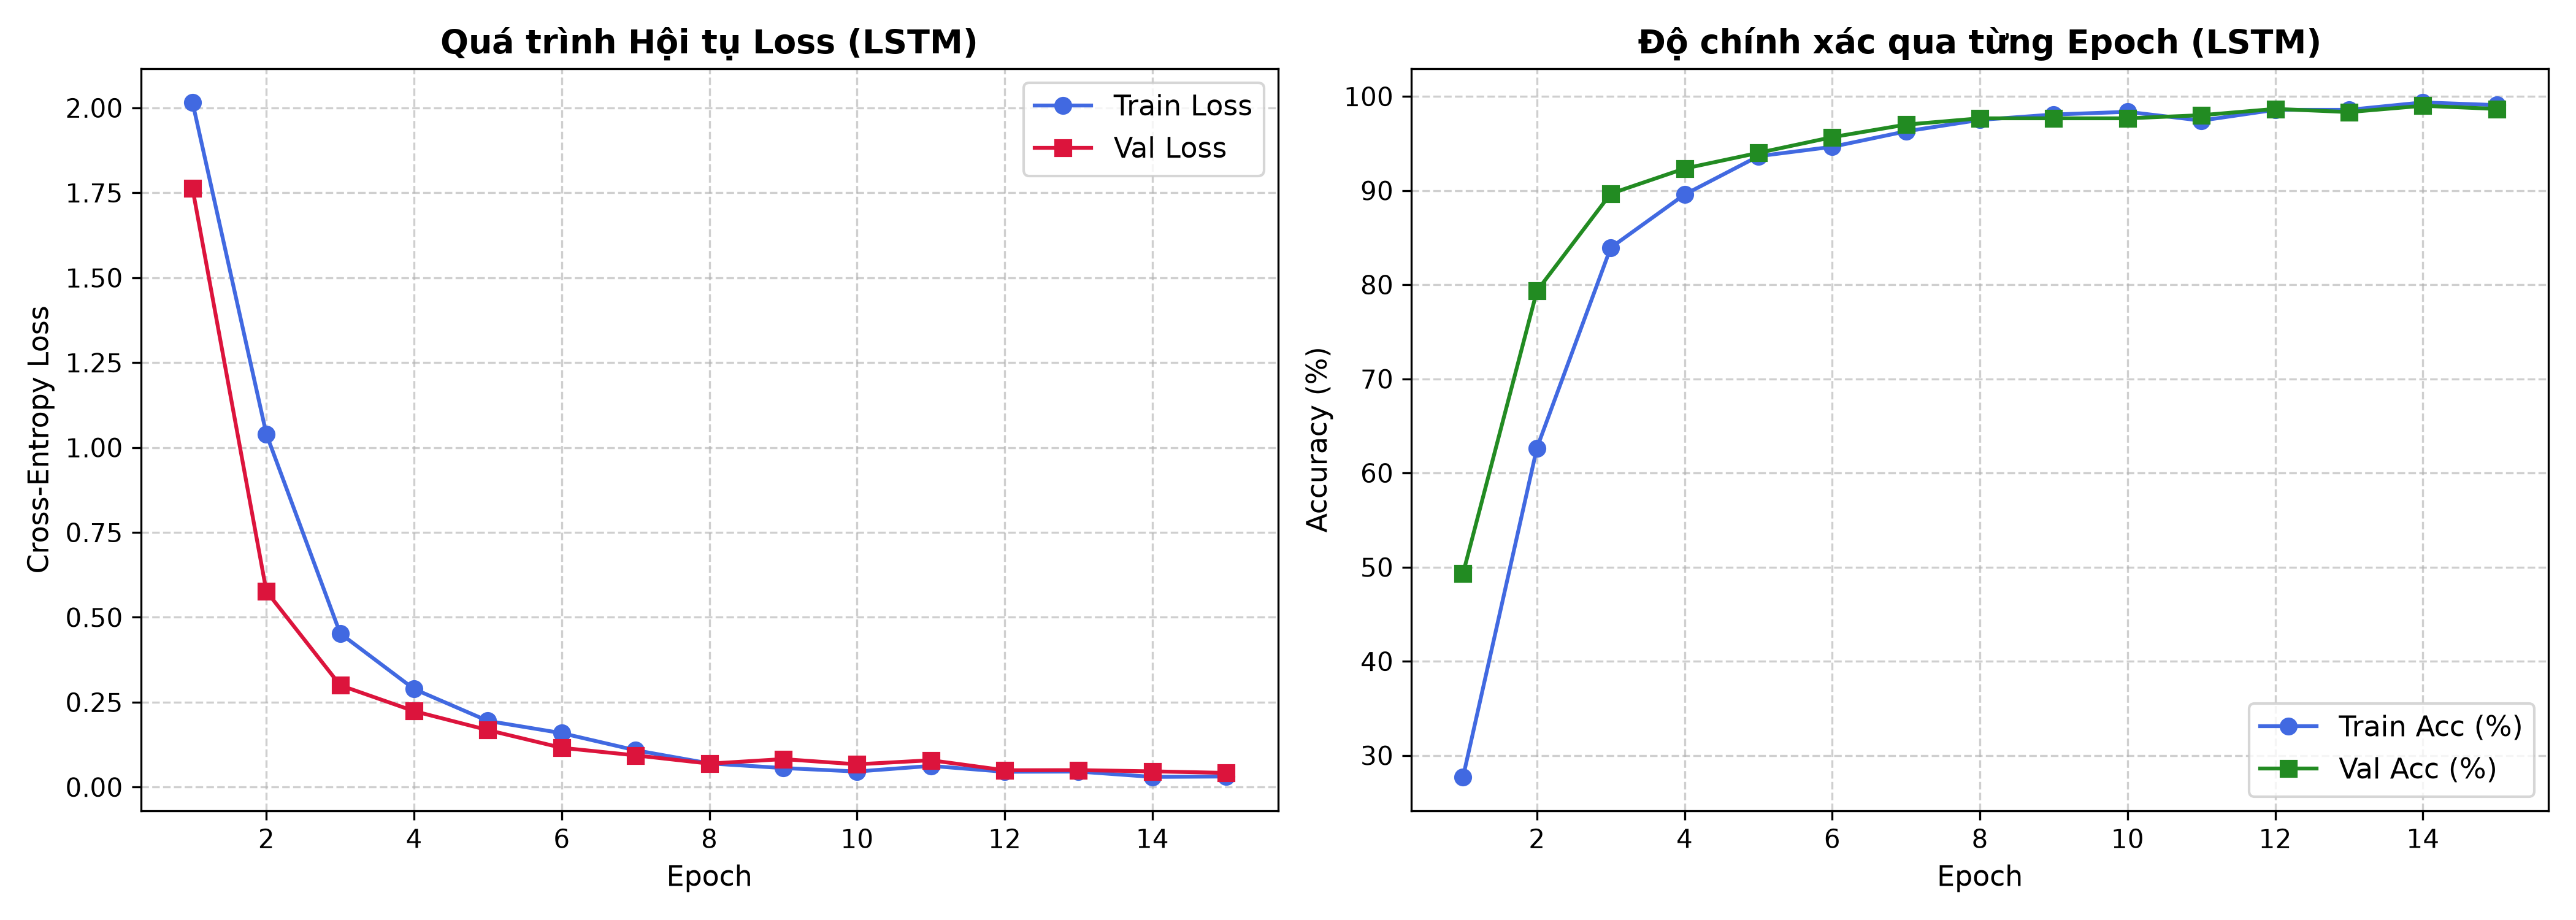

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(lstm_history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ Loss
axes[0].plot(epochs_range, lstm_history['train_loss'], label='Train Loss', color='royalblue', marker='o')
axes[0].plot(epochs_range, lstm_history['val_loss'], label='Val Loss', color='crimson', marker='s')
axes[0].set_title('Quá trình Hội tụ Loss (LSTM)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=11)

# 2. Biểu đồ Accuracy
axes[1].plot(epochs_range, [acc * 100 for acc in lstm_history['train_acc']], label='Train Acc (%)', color='royalblue', marker='o')
axes[1].plot(epochs_range, [acc * 100 for acc in lstm_history['val_acc']], label='Val Acc (%)', color='forestgreen', marker='s')
axes[1].set_title('Độ chính xác qua từng Epoch (LSTM)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.savefig('checkpoints/lstm_training_curves.png', dpi=300)
plt.show()

## 5. Đánh giá Mô hình trên Tập Test và Log Kết quả Ban đầu


=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (300 mẫu) ===
Loss tập Test: 0.0324
Độ chính xác tập Test (Test Accuracy): 99.00%

--- BÁO CÁO PHÂN LOẠI CHI TIẾT (Classification Report) ---
                                    precision    recall  f1-score   support

                 Backend Developer     0.9737    1.0000    0.9867        37
                     Cloud Enginee     1.0000    1.0000    1.0000        37
                    Data Scientist     0.9744    1.0000    0.9870        38
                Frontend Developer     0.9744    1.0000    0.9870        38
              Full Stack Developer     1.0000    0.9737    0.9867        38
         Machine Learning Engineer     1.0000    1.0000    1.0000        37
Mobile App Developer (iOS/Android)     1.0000    0.9737    0.9867        38
                  Python Developer     1.0000    0.9730    0.9863        37

                          accuracy                         0.9900       300
                         macro avg     0.9903    0.9900    0

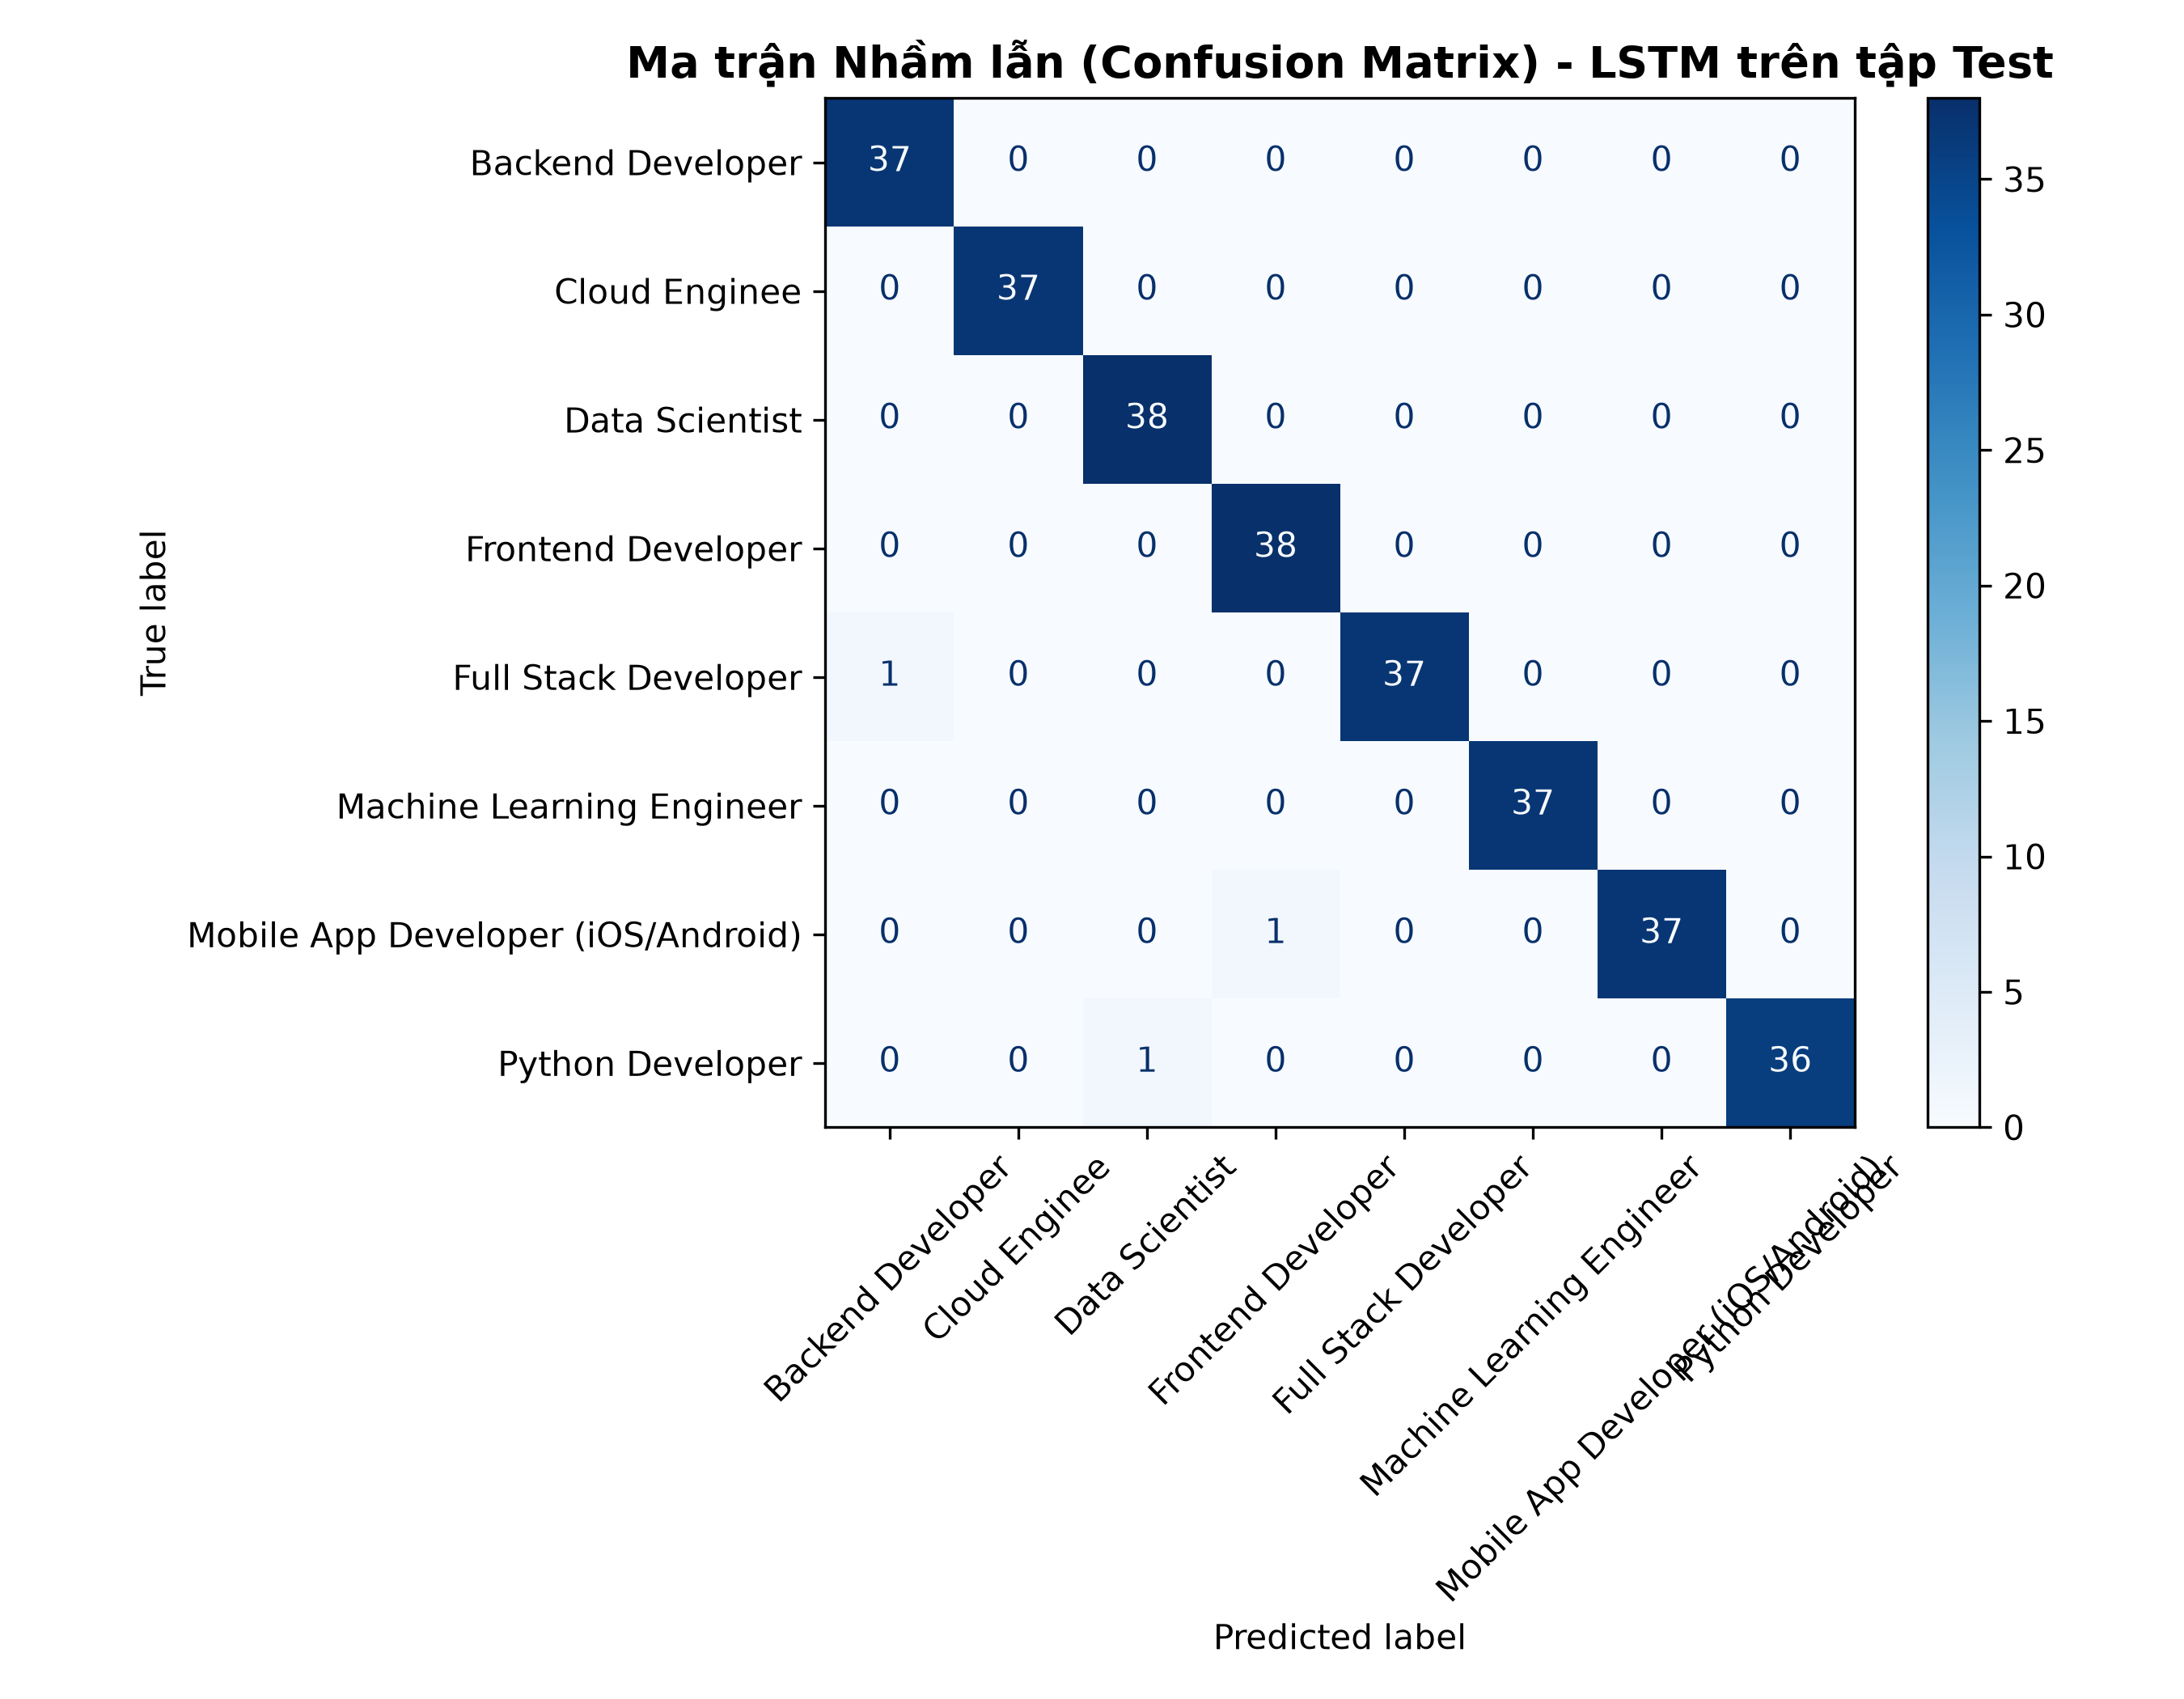

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Tải trọng số tốt nhất
lstm_model.load_state_dict(torch.load(best_lstm_ckpt))
criterion = nn.CrossEntropyLoss()
test_loss, test_acc, test_preds, test_labels = evaluate(lstm_model, test_loader, criterion, device)

print(f"\n=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ({len(test_loader.dataset)} mẫu) ===")
print(f"Loss tập Test: {test_loss:.4f}")
print(f"Độ chính xác tập Test (Test Accuracy): {test_acc * 100:.2f}%")

target_names = [id_to_category[i] for i in range(len(category_to_id))]
print("\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT (Classification Report) ---")
print(classification_report(test_labels, test_preds, target_names=target_names, digits=4))

# Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(test_labels, test_preds)
fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=True)
ax.set_title('Ma trận Nhầm lẫn (Confusion Matrix) - LSTM trên tập Test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('checkpoints/lstm_confusion_matrix.png', dpi=300)
plt.show()

## 6. Huấn luyện Baseline Simple RNN để So sánh Đối chiếu

In [ ]:
rnn_model = TechTrailRNN(
    vocab_size=len(vocab),
    embed_dim=128,
    hidden_dim=128,
    num_classes=len(category_to_id),
    dropout=0.3
).to(device)

rnn_history, best_rnn_ckpt = train_model(
    rnn_model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.002,
    patience=5,
    save_name='best_rnn_model.pt'
)

# Đánh giá Simple RNN trên tập Test
rnn_model.load_state_dict(torch.load(best_rnn_ckpt))
r_test_loss, r_test_acc, r_preds, r_labels = evaluate(rnn_model, test_loader, criterion, device)
print(f"\nSimple RNN - Test Accuracy: {r_test_acc * 100:.2f}% | Test Loss: {r_test_loss:.4f}")

Bắt đầu huấn luyện mô hình (15 epochs tối đa)...
Epoch    | Train Loss   | Train Acc   | Val Loss    | Val Acc    | Trạng thái
01/15    | 1.9230       | 29.07     % | 1.3951      | 64.67    % | (*) Lưu model tốt nhất
02/15    | 0.8183       | 73.64     % | 0.3750      | 87.33    % | (*) Lưu model tốt nhất
03/15    | 0.3502       | 87.07     % | 0.2004      | 93.00    % | (*) Lưu model tốt nhất
04/15    | 0.2089       | 92.79     % | 0.1378      | 95.00    % | (*) Lưu model tốt nhất
05/15    | 0.1340       | 95.71     % | 0.0951      | 97.00    % | (*) Lưu model tốt nhất
06/15    | 0.0925       | 96.93     % | 0.0689      | 97.67    % | (*) Lưu model tốt nhất
07/15    | 0.0608       | 98.43     % | 0.0369      | 99.00    % | (*) Lưu model tốt nhất
08/15    | 0.0511       | 98.43     % | 0.0556      | 97.67    % | 
09/15    | 0.0496       | 98.71     % | 0.0561      | 98.67    % | 
10/15    | 0.0360       | 99.00     % | 0.0453      | 98.00    % | 
11/15    | 0.0307       | 99.00     % |